# Parte III. Sistemas de recomendación

**Integrantes:** Ricardo Acuña, Juan Aquino y Camilo Soto.

**Pregunta que responde.** ¿Es predecible con quién contrata una entidad, y qué relaciones se salen de lo esperable? El recomendador no se construye para decirle a una entidad a quién contratar, que sería prescriptivo y ajeno a la ley de contrataciones, sino como **modelo del mercado**: si sabe predecir bien las relaciones nuevas de un año a partir de los anteriores, entonces una relación que el modelo considera muy improbable es, por definición, inusual, y eso es lo que interesa a quien supervisa.

**El planteamiento.** Las entidades son los usuarios, los proveedores son los ítems, y la señal es implícita: el número de adjudicaciones. No hay calificaciones ni rechazos explícitos; que una entidad no haya contratado a un proveedor no dice que no le guste.

**Dónde corre.** El ALS de Spark MLlib en Spark; el vecindario, el contenido y la evaluación en local con numpy y scipy. La sección 6 justifica la división con tiempos medidos.

In [1]:
import sys, time
from pathlib import Path

# Los ayudantes del proyecto viven en notebooks/scripts. Se importan por
# nombre, no con asterisco, para que quede claro de donde sale cada uno.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "notebooks" / "scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import Window
from pyspark.sql import functions as F

from helpers import (PARQUET, BASE, FIGS, ARTEFACTOS, FIGURAS, HALLAZGOS, PALETA,
                     AZUL, ROJO, VERDE, MORADO, TEAL, TINTA, SUAVE, REJILLA, fmt, MILES,
                     abrir_spark, cronometro, medir, figura, exportar, hallazgo,
                     barras_h, lineas, barras_agrupadas, mapa_calor, gini)
from scipy import sparse
from algoritmos import normalizar_filas, tfidf, vecinos_usuario, puntaje_vecinos, top_k, metricas_ranking
from relacional import SIN_CONCURSO

pd.set_option("display.width", 190)
pd.set_option("display.max_colwidth", 64)


spark = abrir_spark("P2-III-Recomendacion", memoria="3g")
ep = spark.read.parquet(str(BASE / "interaccion_entidad_proveedor")).toPandas()
hechos = spark.read.parquet(str(BASE / "hechos")).select(
    "comprador_id", "clave", "familia", "departamento", "anio", "n_postores", "metodo", "monto", "ocid").toPandas()
entidades = spark.read.parquet(str(BASE / "caracteristicas_entidades")).select(
    "comprador_id", "comprador_nombre", "departamento", "nivel_gobierno").toPandas()
nombres = spark.read.parquet(str(BASE / "caracteristicas_proveedores")).select("clave", "nombre").toPandas()
print(f"{len(ep):,} celdas entidad, proveedor y año; {len(hechos):,} adjudicaciones")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/17 22:19:24 WARN Utils: Your hostname, germain-ThinkPad-E15-Gen-2, resolves to a loopback address: 127.0.1.1; using 192.168.1.27 instead (on interface wlp0s20f3)
26/10/17 22:19:24 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/17 22:19:26 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


125,757 celdas entidad, proveedor y año; 156,629 adjudicaciones


## 1. La matriz de interacción y la partición temporal

**Entrenamiento con 2023 y 2024, prueba con 2025.** Una partición aleatoria de celdas sería tramposa: dejaría en el entrenamiento adjudicaciones de 2025 que ayudan a predecir otras del mismo año. La temporal reproduce el uso real, que es predecir el año que viene con lo que ya pasó.

**Qué se predice.** Solo las **relaciones nuevas**: pares entidad y proveedor que aparecen en 2025 y no existían en el entrenamiento. La Parte I mostró que tres de cada cuatro relaciones de un año son nuevas; predecir una repetición es trivial y no requiere un recomendador. Lo que vale es anticipar la relación nueva, porque es la mayoría y porque es la que el modelo después puede declarar inusual.

**La señal.** El número de adjudicaciones del par en el período de entrenamiento, comprimido con log(1 + n) para que una entidad que contrata cien veces al mismo proveedor no domine la similitud.

In [2]:
ENTRENA, PRUEBA = [2023, 2024], 2025
tr = ep[ep.anio.isin(ENTRENA)].groupby(["comprador_id", "clave"], as_index=False).n.sum()
te = ep[ep.anio == PRUEBA].groupby(["comprador_id", "clave"], as_index=False).n.sum()

usuarios = pd.Index(sorted(tr.comprador_id.unique()))
items = pd.Index(sorted(tr.clave.unique()))
u_tr, i_tr = usuarios.get_indexer(tr.comprador_id), items.get_indexer(tr.clave)
R = sparse.csr_matrix((np.log1p(tr.n.values), (u_tr, i_tr)), shape=(len(usuarios), len(items)))
conocidos = sparse.csr_matrix((np.ones(len(tr)), (u_tr, i_tr)), shape=R.shape)

nuevos = te.merge(tr[["comprador_id", "clave"]], how="left", indicator=True)
nuevos = nuevos[nuevos._merge == "left_only"].drop(columns="_merge")
alcanzables = nuevos[nuevos.comprador_id.isin(usuarios) & nuevos.clave.isin(items)]
relevantes = [set() for _ in usuarios]
for u, i in zip(usuarios.get_indexer(alcanzables.comprador_id), items.get_indexer(alcanzables.clave)):
    relevantes[u].add(i)

desglose = pd.DataFrame([
    {"pares_2025": "se repiten de 2023 o 2024", "pares": len(te) - len(nuevos)},
    {"pares_2025": "nuevos, proveedor sin historia", "pares": int((~nuevos.clave.isin(items)).sum())},
    {"pares_2025": "nuevos, entidad sin historia", "pares": int((nuevos.clave.isin(items) & ~nuevos.comprador_id.isin(usuarios)).sum())},
    {"pares_2025": "nuevos y predecibles", "pares": len(alcanzables)}])
desglose["pct"] = (100 * desglose.pares / len(te)).round(1)
exportar(desglose, "p3_desglose_prueba", "Composicion de los pares entidad y proveedor de 2025")
print(f"matriz de entrenamiento: {R.shape[0]:,} entidades x {R.shape[1]:,} proveedores, "
      f"{R.nnz:,} celdas, densidad {100*R.nnz/np.prod(R.shape):.3f} %")
print(f"{sum(1 for r in relevantes if r):,} entidades con al menos una relación nueva predecible")
desglose

matriz de entrenamiento: 2,828 entidades x 48,380 proveedores, 80,033 celdas, densidad 0.058 %
2,129 entidades con al menos una relación nueva predecible


,pares_2025,pares,pct
0,se repiten de 2023 o 2024,9861,26.3
1,"nuevos, proveedor sin historia",16155,43.0
2,"nuevos, entidad sin historia",97,0.3
3,nuevos y predecibles,11416,30.4



Lectura de f16_desglose_prueba
Solo el 30 por ciento de las relaciones de 2025 son nuevas y además predecibles, en el sentido de que tanto la entidad como el proveedor tienen historia. El 26 por ciento repite una relación anterior y el 43 por ciento involucra a un proveedor que no había ganado nada en 2023 y 2024: ese es el arranque en frío, y ningún filtrado colaborativo puede anticiparlo porque el proveedor no tiene fila en la matriz. Es también una buena noticia para la competencia: cada año entra una fracción grande de proveedores nuevos al mercado estatal.



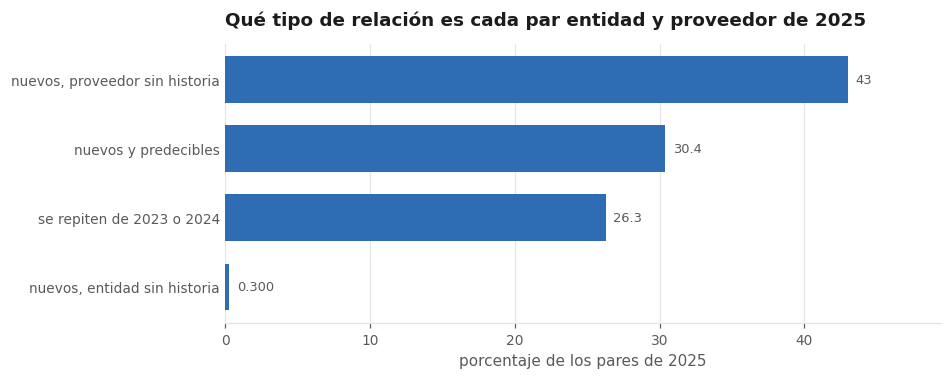

In [3]:
fig, ax = barras_h(desglose, "pares_2025", "pct", "Qué tipo de relación es cada par entidad y proveedor de 2025",
                   "porcentaje de los pares de 2025", color=AZUL, alto=.55)
d = desglose.set_index("pares_2025").pct
figura(fig, "f16_desglose_prueba", f"""
Solo el {d['nuevos y predecibles']:.0f} por ciento de las relaciones de 2025 son nuevas y además
predecibles, en el sentido de que tanto la entidad como el proveedor tienen historia. El
{d['se repiten de 2023 o 2024']:.0f} por ciento repite una relación anterior y el
{d['nuevos, proveedor sin historia']:.0f} por ciento involucra a un proveedor que no había ganado
nada en 2023 y 2024: ese es el arranque en frío, y ningún filtrado colaborativo puede anticiparlo
porque el proveedor no tiene fila en la matriz. Es también una buena noticia para la competencia:
cada año entra una fracción grande de proveedores nuevos al mercado estatal.""")

## 2. Líneas base

Antes de cualquier modelo hay que saber cuánto se acierta sin modelo. Dos líneas base:

1. **Popularidad global.** Recomendar a todas las entidades los proveedores con más clientes distintos.
2. **Popularidad en el departamento.** Recomendar los proveedores con más clientes en el departamento de la entidad. Es la línea base honesta en contratación pública, donde la mayoría de proveedores opera en su región.

Todos los métodos se evalúan igual: diez recomendaciones por entidad, excluyendo los proveedores que ya contrató, y se mide precisión, recall y NDCG en 10 contra sus relaciones nuevas de 2025. Además se registra la **cobertura**, la fracción del catálogo que aparece en alguna recomendación, porque un método que recomienda siempre los mismos cincuenta proveedores puede tener buen recall y no servir para nada.

In [4]:
K_REC = 10
LOTE = 64            # lotes pequenos: cada fila de puntajes ocupa todo el catalogo
filas_eval = [u for u in range(len(usuarios)) if relevantes[u]]
resultados, recomendaciones = [], {}

def evaluar(nombre, puntuar, segundos=None):
    """puntuar(filas) devuelve la matriz de puntajes de esas entidades sobre todo el catálogo."""
    t0 = time.perf_counter()
    rec = []
    for a in range(0, len(filas_eval), LOTE):
        f = filas_eval[a:a + LOTE]
        rec.append(top_k(puntuar(f), K_REC, conocidos[f]))
    rec = np.vstack(rec)
    m = metricas_ranking(rec, [relevantes[u] for u in filas_eval], K_REC)
    m.update({"metodo": nombre, "cobertura_pct": 100 * len(np.unique(rec)) / len(items),
              "segundos": segundos if segundos is not None else time.perf_counter() - t0})
    resultados.append(m); recomendaciones[nombre] = rec
    print(f"{nombre:34s} P@10 {m['precision']:.4f}  R@10 {m['recall']:.4f}  "
          f"NDCG@10 {m['ndcg']:.4f}  cobertura {m['cobertura_pct']:.2f} %")

grado_item = np.asarray(conocidos.sum(0)).ravel()
evaluar("popularidad global", lambda f: np.tile(grado_item, (len(f), 1)))

depto = entidades.set_index("comprador_id").departamento.reindex(usuarios).fillna("SIN DEPARTAMENTO")
deptos = pd.Index(sorted(depto.unique()))
D = sparse.csr_matrix((np.ones(len(usuarios)), (deptos.get_indexer(depto), np.arange(len(usuarios)))),
                      shape=(len(deptos), len(usuarios)))
pop_depto = (D @ conocidos).toarray()
fila_depto = deptos.get_indexer(depto)
evaluar("popularidad en el departamento", lambda f: pop_depto[fila_depto[f]] + 1e-3 * grado_item)

popularidad global                 P@10 0.0116  R@10 0.0264  NDCG@10 0.0223  cobertura 0.04 %


popularidad en el departamento     P@10 0.0275  R@10 0.0803  NDCG@10 0.0661  cobertura 0.77 %


## 3. Filtrado colaborativo de vecindario, usuario a usuario

La hipótesis de la lecture: entidades que contrataron a los mismos proveedores en el pasado contratarán a proveedores parecidos en el futuro. Para cada entidad se buscan las k entidades más similares por coseno y se predice el puntaje de cada proveedor como el promedio de sus señales ponderado por la similitud.

**Por qué usuario a usuario y no ítem a ítem.** La lecture recomienda ítem a ítem porque en un comercio los ítems son pocos y estables y los usuarios muchos. Aquí es al revés: hay unas 2.900 entidades y más de cincuenta mil proveedores, y la mayoría de proveedores tiene un solo cliente, de modo que la similitud entre dos proveedores casi siempre se calcula sobre una o ninguna entidad en común. La matriz entidad por entidad, en cambio, es pequeña, densa en información y cabe entera en memoria.

**Por qué coseno y no Pearson.** Pearson centra las calificaciones para corregir a usuarios generosos o exigentes. Con señal implícita no hay calificaciones bajas que centrar: una celda vacía no es un rechazo, y restar la media convertiría todas las celdas vacías en valoraciones negativas. Se usa coseno sobre log(1 + n).

El k se elige con una validación interna: entrenar con 2023 y predecir las relaciones nuevas de 2024.

In [5]:
# Validacion: 2023 para entrenar, relaciones nuevas de 2024 para elegir k.
tr_v = ep[ep.anio == 2023].groupby(["comprador_id", "clave"], as_index=False).n.sum()
va_v = ep[ep.anio == 2024].groupby(["comprador_id", "clave"], as_index=False).n.sum()
u_v, i_v = pd.Index(sorted(tr_v.comprador_id.unique())), pd.Index(sorted(tr_v.clave.unique()))
R_v = sparse.csr_matrix((np.log1p(tr_v.n.values), (u_v.get_indexer(tr_v.comprador_id), i_v.get_indexer(tr_v.clave))),
                        shape=(len(u_v), len(i_v)))
con_v = (R_v > 0).astype(float)
nv = va_v.merge(tr_v[["comprador_id", "clave"]], how="left", indicator=True)
nv = nv[(nv._merge == "left_only") & nv.comprador_id.isin(u_v) & nv.clave.isin(i_v)]
rel_v = [set() for _ in u_v]
for u, i in zip(u_v.get_indexer(nv.comprador_id), i_v.get_indexer(nv.clave)):
    rel_v[u].add(i)
filas_v = [u for u in range(len(u_v)) if rel_v[u]]

def validar(puntuar):
    rec = np.vstack([top_k(puntuar(filas_v[a:a + LOTE]), K_REC, con_v[filas_v[a:a + LOTE]])
                     for a in range(0, len(filas_v), LOTE)])
    return metricas_ranking(rec, [rel_v[u] for u in filas_v], K_REC)["ndcg"]

val_k = []
for k in [10, 25, 50, 100, 200]:
    S_v = vecinos_usuario(R_v, k)
    val_k.append({"k": k, "ndcg_validacion": validar(lambda f: puntaje_vecinos(S_v, R_v, f))})
val_k = pd.DataFrame(val_k)
K_VEC = int(val_k.loc[val_k.ndcg_validacion.idxmax(), "k"])
exportar(val_k.round(5), "p3_validacion_k", "NDCG de validacion del vecindario segun k")
print(f"k elegido por validación: {K_VEC}")
val_k.round(4)

k elegido por validación: 50


,k,ndcg_validacion
0,10,0.0583
1,25,0.0748
2,50,0.0812
3,100,0.0806
4,200,0.0800


In [6]:
t0 = time.perf_counter()
S = vecinos_usuario(R, K_VEC)
t_sim = time.perf_counter() - t0
evaluar(f"vecindario usuario a usuario, k = {K_VEC}", lambda f: puntaje_vecinos(S, R, f))

vecindario usuario a usuario, k = 50 P@10 0.0350  R@10 0.0831  NDCG@10 0.0756  cobertura 7.46 %


## 4. Basado en contenido

La hipótesis: a una entidad le corresponden proveedores con características parecidas a las de los que ya contrató. Las características de un proveedor salen de lo que vende y de dónde lo vende:

1. **Familias CUBSO** de sus adjudicaciones, por ejemplo medicamentos o alquiler de maquinaria.
2. **Departamentos** donde ganó, porque en contratación pública la geografía pesa tanto como el rubro.

Cada proveedor es un documento cuyos términos son esas familias y esos departamentos, ponderado con **TF-IDF** como en la lecture: una familia que vende casi todo el mundo, como útiles de oficina, pesa poco; una familia rara pesa mucho. El perfil de la entidad es el promedio de los vectores de los proveedores que contrató, ponderado por su señal, y la predicción es el coseno entre el perfil de la entidad y el de cada proveedor.

La ventaja frente al vecindario es que no necesita que otra entidad haya contratado al proveedor: basta con saber qué vende y dónde.

In [7]:
h_tr = hechos[hechos.anio.isin(ENTRENA) & hechos.clave.isin(items)]
terminos_f = "F" + h_tr.familia.fillna("SIN")
terminos_d = "D" + h_tr.departamento.fillna("SIN")
doc = pd.concat([pd.DataFrame({"clave": h_tr.clave, "t": terminos_f}),
                 pd.DataFrame({"clave": h_tr.clave, "t": terminos_d})])
doc = doc[doc.t != "FSIN"].groupby(["clave", "t"]).size().reset_index(name="c")
vocab = pd.Index(sorted(doc.t.unique()))
M = sparse.csr_matrix((doc.c.values, (items.get_indexer(doc.clave), vocab.get_indexer(doc.t))),
                      shape=(len(items), len(vocab)))
perfil_item = normalizar_filas(tfidf(M))
perfil_usuario = normalizar_filas(sparse.csr_matrix(R @ perfil_item))
print(f"vocabulario: {len(vocab)} términos, {sum(v.startswith('F') for v in vocab)} familias "
      f"y {sum(v.startswith('D') for v in vocab)} departamentos")
evaluar("contenido, TF-IDF de familia y departamento",
        lambda f: (perfil_usuario[f] @ perfil_item.T).toarray())

vocabulario: 383 términos, 358 familias y 25 departamentos


contenido, TF-IDF de familia y departamento P@10 0.0051  R@10 0.0136  NDCG@10 0.0105  cobertura 14.97 %


## 5. Factores latentes con ALS de Spark MLlib

La lecture motiva los factores latentes con dos límites del vecindario: la similitud es una elección heurística y solo mira pares, sin aprovechar que si A se parece a B y B a C, algo dice eso de A y C. La factorización aprende un vector de r factores por entidad y otro por proveedor, y predice con su producto punto.

Con señal implícita no se minimiza el error sobre calificaciones, porque no las hay. El ALS implícito de Hu, Koren y Volinsky, que es el que implementa MLlib con implicitPrefs, trata cada celda como una preferencia binaria, 1 si hubo contrato y 0 si no, con una **confianza** 1 + alfa por la señal: los ceros cuentan, pero poco, y los contratos repetidos cuentan mucho. Alterna entre fijar los factores de proveedor y resolver los de entidad por mínimos cuadrados, y viceversa, que es lo que lo hace paralelizable.

Se eligen el rango, la regularización y alfa con la misma validación 2023 contra 2024.

In [8]:
from pyspark.ml.recommendation import ALS

def ajustar_als(Rm, rango, reg, alfa, iters=12):
    c = Rm.tocoo()
    df = spark.createDataFrame(pd.DataFrame({"u": c.row.astype("int32"), "i": c.col.astype("int32"),
                                             "r": np.expm1(c.data).astype("float32")}))
    m = ALS(rank=rango, regParam=reg, alpha=alfa, maxIter=iters, implicitPrefs=True, userCol="u",
            itemCol="i", ratingCol="r", coldStartStrategy="drop", seed=7).fit(df)
    U = np.zeros((Rm.shape[0], rango), dtype=np.float32); V = np.zeros((Rm.shape[1], rango), dtype=np.float32)
    for r in m.userFactors.collect(): U[r.id] = r.features
    for r in m.itemFactors.collect(): V[r.id] = r.features
    return U, V

grilla = []
for rango in [16, 48]:
    for reg in [0.01, 0.1]:
        for alfa in [5.0, 20.0]:
            Uv, Vv = ajustar_als(R_v, rango, reg, alfa)
            grilla.append({"rango": rango, "reg": reg, "alfa": alfa,
                           "ndcg_validacion": validar(lambda f: Uv[f] @ Vv.T)})
grilla = pd.DataFrame(grilla)
mejor = grilla.loc[grilla.ndcg_validacion.idxmax()]
exportar(grilla.round(5), "p3_validacion_als", "NDCG de validacion de ALS segun rango, regularizacion y alfa")
grilla.round(4)

,rango,reg,alfa,ndcg_validacion
0,16,0.01,5.0,0.0686
1,16,0.01,20.0,0.0752
2,16,0.10,5.0,0.0682
3,16,0.10,20.0,0.0747
4,48,0.01,5.0,0.0847
5,48,0.01,20.0,0.0871
6,48,0.10,5.0,0.0857
7,48,0.10,20.0,0.0872


In [9]:
t0 = time.perf_counter()
U, V = ajustar_als(R, int(mejor.rango), float(mejor.reg), float(mejor.alfa))
t_als = time.perf_counter() - t0
evaluar(f"ALS implícito, rango {int(mejor.rango)}", lambda f: U[f] @ V.T)
print(f"ajuste de ALS en Spark: {t_als:.1f} s; similitud del vecindario en numpy: {t_sim:.1f} s")

ALS implícito, rango 48            P@10 0.0327  R@10 0.0875  NDCG@10 0.0708  cobertura 3.97 %
ajuste de ALS en Spark: 27.4 s; similitud del vecindario en numpy: 0.4 s


## 6. Recomendador híbrido

Los tres enfoques miran cosas distintas: el vecindario, qué hacen las entidades parecidas; el contenido, qué vende y dónde el proveedor; ALS, la estructura global de la matriz. Si se equivocan en casos distintos, combinarlos debería acertar más que cualquiera por separado, que es la lección del premio Netflix que cierra la lecture.

La combinación es deliberadamente simple: los puntajes de cada método se estandarizan por entidad, restando su media y dividiendo por su desviación, para que estén en la misma escala, y se suman. Se añade la popularidad en el departamento como cuarta señal, porque resultó una línea base fuerte. No se ajustan pesos, para no sobreajustar a la validación.

In [10]:
def estandarizar(P):
    P = np.asarray(P, dtype=np.float64)
    return (P - P.mean(1, keepdims=True)) / (P.std(1, keepdims=True) + 1e-12)

def puntaje_hibrido(f):
    return (estandarizar(puntaje_vecinos(S, R, f)) + estandarizar((perfil_usuario[f] @ perfil_item.T).toarray())
            + estandarizar(U[f] @ V.T) + estandarizar(np.log1p(pop_depto[fila_depto[f]])))

evaluar("híbrido: vecindario, contenido, ALS y departamento", puntaje_hibrido)
tabla = pd.DataFrame(resultados)[["metodo", "precision", "recall", "ndcg", "cobertura_pct", "segundos", "usuarios"]]
# Precision esperada de una lista al azar: relevantes medios entre el catalogo.
azar = np.mean([len(relevantes[u]) for u in filas_eval]) / len(items)
exportar(tabla.round(5), "p3_resultados", "Precision, recall, NDCG y cobertura en 10 de cada recomendador")
tabla.round(4)

híbrido: vecindario, contenido, ALS y departamento P@10 0.0401  R@10 0.1042  NDCG@10 0.0875  cobertura 6.02 %


,metodo,precision,recall,ndcg,cobertura_pct,segundos,usuarios
0,popularidad global,0.0116,0.0264,0.0223,0.0351,2.1559,2129
1,popularidad en el departamento,0.0275,0.0803,0.0661,0.7668,2.5459,2129
2,"vecindario usuario a usuario, k = 50",0.0350,0.0831,0.0756,7.4618,6.6498,2129
3,"contenido, TF-IDF de familia y departamento",0.0051,0.0136,0.0105,14.9711,6.6839,2129
4,"ALS implícito, rango 48",0.0327,0.0875,0.0708,3.9748,5.2292,2129
5,"híbrido: vecindario, contenido, ALS y departamento",0.0401,0.1042,0.0875,6.0169,34.6094,2129



Lectura de f17_resultados_recomendacion
El híbrido logra un NDCG en 10 de 0.087 y un recall de 0.104, frente a 0.076 del mejor enfoque individual, vecindario usuario a usuario, k = 50, y 0.066 de la popularidad en el departamento. En términos operativos, de cada cien proveedores que el híbrido propone, 4 son contratados por primera vez por esa entidad en 2025, en un catálogo de 48,380 proveedores donde una lista al azar acertaría 0.011 de cada cien: 361 veces más. La popularidad acierta lo obvio con una cobertura mínima; el vecindario y ALS cubren más catálogo. El contenido solo rinde poco, porque miles de proveedores comparten familia y departamento y el coseno no puede ordenarlos entre sí, aunque es el que más catálogo cubre. Que la suma gane a cada parte indica que se equivocan en casos distintos; la ablación siguiente mide cuánto aporta cada una.



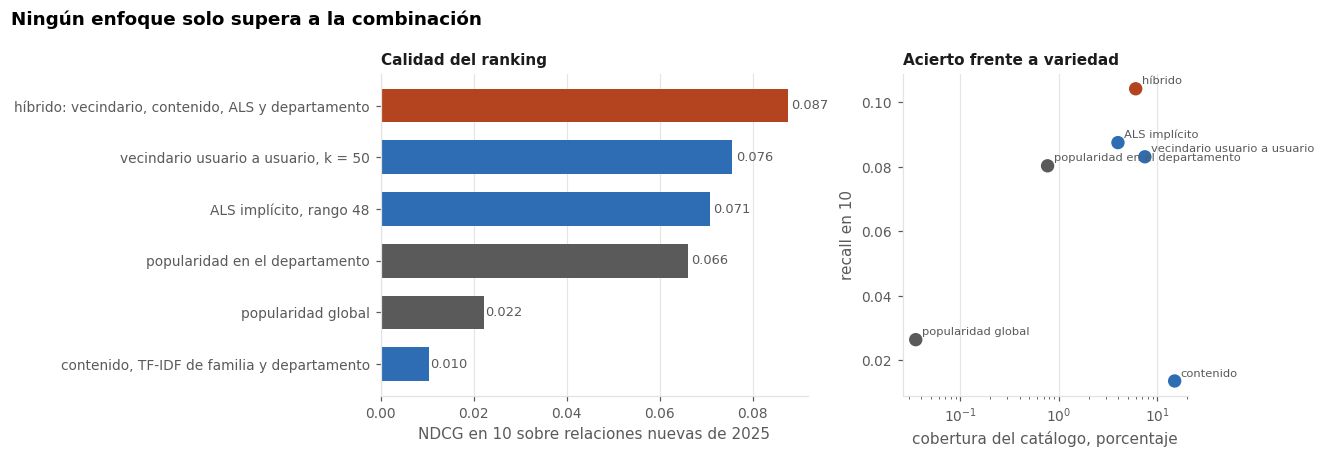

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
orden = tabla.sort_values("ndcg")
colores = [ROJO if "híbrido" in m else (SUAVE if "popularidad" in m else AZUL) for m in orden.metodo]
axes[0].barh(orden.metodo, orden.ndcg, color=colores, height=.65)
for y, v in enumerate(orden.ndcg):
    axes[0].text(v * 1.01, y, f"{v:.3f}", va="center", fontsize=8.5, color=SUAVE)
axes[0].set_xlabel("NDCG en 10 sobre relaciones nuevas de 2025")
axes[0].set_title("Calidad del ranking", loc="left", fontsize=10)
axes[1].scatter(tabla.cobertura_pct, tabla.recall, s=60,
                c=[ROJO if "híbrido" in m else (SUAVE if "popularidad" in m else AZUL) for m in tabla.metodo])
for _, r in tabla.iterrows():
    axes[1].annotate(r.metodo.split(",")[0].split(":")[0], (r.cobertura_pct, r.recall), fontsize=7.5,
                     xytext=(4, 3), textcoords="offset points", color=SUAVE)
axes[1].set_xscale("log"); axes[1].set_xlabel("cobertura del catálogo, porcentaje"); axes[1].set_ylabel("recall en 10")
axes[1].set_title("Acierto frente a variedad", loc="left", fontsize=10)
for ax in axes: ax.grid(alpha=.9, axis="x"); ax.set_axisbelow(True)
fig.suptitle("Ningún enfoque solo supera a la combinación", x=.01, ha="left", fontweight="bold")
fig.tight_layout()
t = tabla.set_index("metodo")
hib = tabla[tabla.metodo.str.startswith("híbrido")].iloc[0]
mejor_solo = tabla[~tabla.metodo.str.startswith(("híbrido", "popularidad"))].sort_values("ndcg").iloc[-1]
base = tabla[tabla.metodo.str.startswith("popularidad en")].iloc[0]
figura(fig, "f17_resultados_recomendacion", f"""
El híbrido logra un NDCG en 10 de {hib.ndcg:.3f} y un recall de {hib.recall:.3f}, frente a
{mejor_solo.ndcg:.3f} del mejor enfoque individual, {mejor_solo.metodo}, y {base.ndcg:.3f} de la
popularidad en el departamento. En términos operativos, de cada cien proveedores que el híbrido
propone, {100*hib.precision:.0f} son contratados por primera vez por esa entidad en 2025, en un
catálogo de {len(items):,} proveedores donde una lista al azar acertaría {100*azar:.3f} de cada cien:
{hib.precision/azar:,.0f} veces más. La popularidad
acierta lo obvio con una cobertura mínima; el vecindario y ALS cubren más catálogo. El contenido solo
rinde poco, porque miles de proveedores comparten familia y departamento y el coseno no puede
ordenarlos entre sí, aunque es el que más catálogo cubre. Que la suma gane a cada parte indica que
se equivocan en casos distintos; la ablación siguiente mide cuánto aporta cada una.""")

**Qué aporta cada señal.** El contenido solo rinde poco, por debajo incluso de la popularidad global. Antes de concluir que sobra en el híbrido se mide: se quita una señal a la vez y se vuelve a evaluar.

In [12]:
senales = {
    "vecindario": lambda f: estandarizar(puntaje_vecinos(S, R, f)),
    "contenido": lambda f: estandarizar((perfil_usuario[f] @ perfil_item.T).toarray()),
    "ALS": lambda f: estandarizar(U[f] @ V.T),
    "departamento": lambda f: estandarizar(np.log1p(pop_depto[fila_depto[f]])),
}
ablacion = []
for fuera in senales:
    resto = [g for n, g in senales.items() if n != fuera]
    rec = np.vstack([top_k(sum(g(filas_eval[a:a + LOTE]) for g in resto), K_REC, conocidos[filas_eval[a:a + LOTE]])
                     for a in range(0, len(filas_eval), LOTE)])
    m = metricas_ranking(rec, [relevantes[u] for u in filas_eval], K_REC)
    ablacion.append({"sin_la_senal": fuera, "ndcg": m["ndcg"], "recall": m["recall"],
                     "cambio_ndcg_pct": 100 * (m["ndcg"] / hib.ndcg - 1)})
ablacion = pd.DataFrame(ablacion)
exportar(ablacion.round(5), "p3_ablacion", "NDCG del hibrido al quitar cada senal")
mas_util = ablacion.loc[ablacion.cambio_ndcg_pct.idxmin()]
cont = ablacion.set_index("sin_la_senal").loc["contenido"]
print(f"la señal cuya ausencia más daña es {mas_util.sin_la_senal}: {mas_util.cambio_ndcg_pct:+.1f} % de NDCG")
print(f"sin contenido el NDCG cambia {cont.cambio_ndcg_pct:+.1f} %")
ablacion.round(4)

la señal cuya ausencia más daña es vecindario: -11.1 % de NDCG
sin contenido el NDCG cambia -2.3 %


,sin_la_senal,ndcg,recall,cambio_ndcg_pct
0,vecindario,0.0778,0.0972,-11.0811
1,contenido,0.0855,0.1001,-2.3020
2,ALS,0.0857,0.0989,-2.0229
3,departamento,0.0826,0.0956,-5.6207


**Spark o local.** El ALS se ajusta en Spark porque su paso de mínimos cuadrados alternos se reparte por bloques de usuarios e ítems, y es la parte que escalaría a millones de entidades y proveedores sin cambiar el código. El vecindario usuario a usuario necesita solo la matriz de similitud entre unas 2.900 entidades, que numpy calcula en un instante con un producto disperso; llevarlo a Spark exigiría un autojoin distribuido para obtener lo mismo más lento. El contenido es un producto de matrices de unos cientos de columnas. **A esta escala Spark aporta en ALS y no en el resto**, y si el número de entidades creciera dos órdenes de magnitud, el vecindario sería el primero en necesitar Spark o una búsqueda aproximada de vecinos como la de la Parte III del proyecto 1.

In [13]:
hallazgo("III", "Las relaciones nuevas siguen patrones que se pueden modelar",
         f"""Con lo ocurrido en 2023 y 2024, el híbrido recupera en su lista de diez el
         {100*hib.recall:.0f} por ciento de las relaciones nuevas de 2025 de cada entidad, con una precisión
         {hib.precision/azar:,.0f} veces la del azar y un NDCG {100*(hib.ndcg/base.ndcg - 1):.0f} por ciento
         mayor que la popularidad regional. No es un oráculo, pero sí una medida útil de qué tan esperable
         es una relación nueva dado el rubro, la geografía y lo que hacen entidades parecidas.""",
         """Usar el puntaje del modelo como medida de qué tan esperable es cada relación nueva, y no como
         sugerencia de contratación; la sección 7 convierte ese puntaje en una alerta.""",
         "f17_resultados_recomendacion, p3_resultados")


HALLAZGO. Las relaciones nuevas siguen patrones que se pueden modelar
Con lo ocurrido en 2023 y 2024, el híbrido recupera en su lista de diez el 10 por ciento de las relaciones nuevas de 2025 de cada entidad, con una precisión 361 veces la del azar y un NDCG 32 por ciento mayor que la popularidad regional. No es un oráculo, pero sí una medida útil de qué tan esperable es una relación nueva dado el rubro, la geografía y lo que hacen entidades parecidas.
Accion propuesta: Usar el puntaje del modelo como medida de qué tan esperable es cada relación nueva, y no como sugerencia de contratación; la sección 7 convierte ese puntaje en una alerta.



## 7. Interpretación: afinidades inusuales y proveedores sustitutos

### 7.1 Relaciones nuevas improbables

Para cada relación nueva de 2025 se calcula en qué percentil de los puntajes híbridos de su entidad cae el proveedor contratado. Un percentil alto significa que el modelo la esperaba; uno bajo, que nada en la historia de la entidad, de las entidades parecidas ni del rubro del proveedor la anticipaba.

La pregunta es si esa sorpresa dice algo más allá del propio modelo. Se contrasta contra dos variables que el modelo **nunca vio**: si el proceso tuvo un solo postor y si se contrató sin concurso. La comparación es entre las relaciones improbables, debajo del percentil 50, y las esperadas, desde el percentil 95, con una prueba de dos proporciones para no confundir una diferencia con ruido de muestreo.

In [14]:
pct_rel = []
filas_ent = [u for u in range(len(usuarios)) if relevantes[u]]
for a in range(0, len(filas_ent), LOTE):
    f = filas_ent[a:a + LOTE]
    P = puntaje_hibrido(f)
    P[conocidos[f].nonzero()] = -np.inf
    validos = np.isfinite(P).sum(1)
    for k, u in enumerate(f):
        fila = P[k]
        for i in relevantes[u]:
            pct_rel.append({"comprador_id": usuarios[u], "clave": items[i],
                            "percentil": 100 * (fila < fila[i]).sum() / validos[k]})
pct_rel = pd.DataFrame(pct_rel)
h25 = hechos[hechos.anio == PRUEBA].assign(
    postor_unico=lambda d: (d.n_postores <= 1).astype(float),
    sin_concurso=lambda d: d.metodo.isin(SIN_CONCURSO).astype(float))
h25 = h25.groupby(["comprador_id", "clave"]).agg(
    monto=("monto", "sum"), postor_unico=("postor_unico", "mean"),
    sin_concurso=("sin_concurso", "mean"), adjudicaciones=("ocid", "nunique")).reset_index()
sorpresa = pct_rel.merge(h25, on=["comprador_id", "clave"])
sorpresa["tramo"] = pd.cut(sorpresa.percentil, [0, 50, 80, 95, 99, 100.01], right=False,
                           labels=["menos de 50", "50 a 80", "80 a 95", "95 a 99", "99 o más"])
por_tramo = sorpresa.groupby("tramo", observed=True).agg(
    relaciones=("clave", "size"), pct_postor_unico=("postor_unico", "mean"),
    pct_sin_concurso=("sin_concurso", "mean"), monto_mediano=("monto", "median")).reset_index()
por_tramo[["pct_postor_unico", "pct_sin_concurso"]] = (100 * por_tramo[["pct_postor_unico", "pct_sin_concurso"]]).round(1)
exportar(por_tramo, "p3_sorpresa", "Postor unico y sin concurso segun lo esperable que era la relacion nueva")

# Prueba de dos proporciones: improbables, debajo del percentil 50, contra esperadas, desde el 95.
from scipy.stats import norm
def dos_proporciones(col):
    a = sorpresa[sorpresa.percentil < 50][col].round(); b = sorpresa[sorpresa.percentil >= 95][col].round()
    p1, p2, n1, n2 = a.mean(), b.mean(), len(a), len(b)
    p = (a.sum() + b.sum()) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    return {"variable": col, "improbables_pct": 100 * p1, "esperadas_pct": 100 * p2,
            "n_improbables": n1, "n_esperadas": n2, "z": z, "p_valor": 2 * (1 - norm.cdf(abs(z)))}
prueba = pd.DataFrame([dos_proporciones("postor_unico"), dos_proporciones("sin_concurso")])
exportar(prueba.round(4), "p3_prueba_sorpresa", "Prueba de dos proporciones entre relaciones improbables y esperadas")
prueba.round(4)

,variable,improbables_pct,esperadas_pct,n_improbables,n_esperadas,z,p_valor
0,postor_unico,5.8651,5.3430,682,8441,0.5812,0.5611
1,sin_concurso,7.1848,6.3381,682,8441,0.8689,0.3849



Lectura de f18_sorpresa
Se contrastan las 682 relaciones nuevas que el modelo consideraba improbables, por debajo del percentil 50 de su entidad, con las 8,441 que esperaba, desde el percentil 95, en dos variables que el modelo nunca vio. Postor único: 5.9 frente a 5.3 por ciento, diferencia que no es significativa, p = 0.56. Sin concurso: 7.2 frente a 6.3 por ciento, diferencia que no es significativa, p = 0.38. La sorpresa del modelo, por sí sola, no anticipa una adjudicación con menos competencia: las relaciones improbables se adjudican como las demás. Es un resultado negativo útil, porque descarta usar el percentil como alerta aislada.



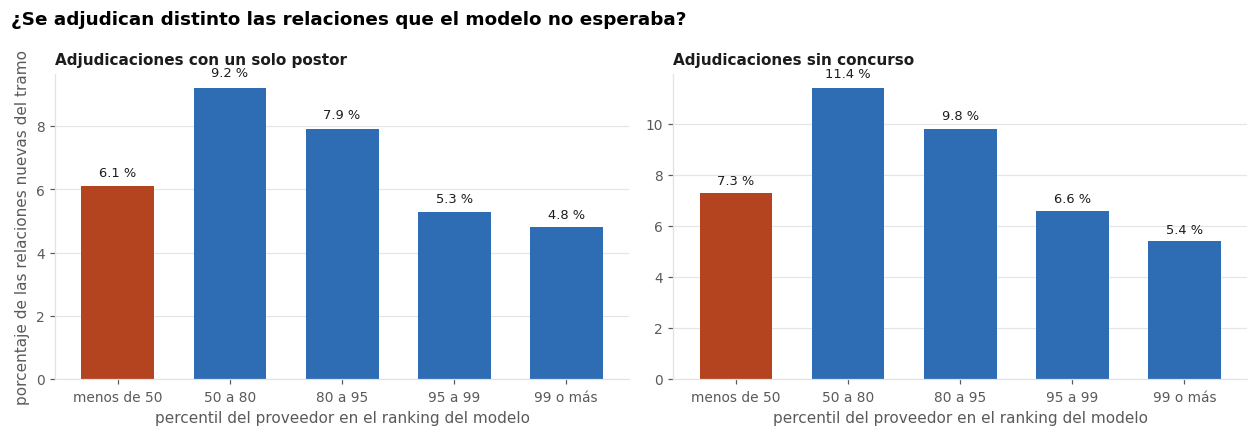

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4), sharey=False)
for ax, col, titulo in [(axes[0], "pct_postor_unico", "con un solo postor"),
                        (axes[1], "pct_sin_concurso", "sin concurso")]:
    ax.bar(por_tramo.tramo.astype(str), por_tramo[col], color=[ROJO] + [AZUL] * (len(por_tramo) - 1), width=.65)
    for x, v in enumerate(por_tramo[col]):
        ax.text(x, v * 1.02 + .2, f"{v:.1f} %", ha="center", fontsize=8.5, color=TINTA)
    ax.set_title(f"Adjudicaciones {titulo}", loc="left", fontsize=10)
    ax.set_xlabel("percentil del proveedor en el ranking del modelo")
    ax.grid(axis="y", alpha=.9); ax.set_axisbelow(True)
axes[0].set_ylabel("porcentaje de las relaciones nuevas del tramo")
fig.suptitle("¿Se adjudican distinto las relaciones que el modelo no esperaba?", x=.01, ha="left", fontweight="bold")
fig.tight_layout()
pu, sc = prueba.set_index("variable").loc["postor_unico"], prueba.set_index("variable").loc["sin_concurso"]
def frase(r, nombre):
    if r.p_valor < .05:
        return (f"{nombre}: {r.improbables_pct:.1f} por ciento en las improbables frente a "
                f"{r.esperadas_pct:.1f} en las esperadas, diferencia significativa con p = {r.p_valor:.3f}")
    return (f"{nombre}: {r.improbables_pct:.1f} frente a {r.esperadas_pct:.1f} por ciento, diferencia "
            f"que no es significativa, p = {r.p_valor:.2f}")
alguna = (prueba.p_valor < .05) & (prueba.improbables_pct > prueba.esperadas_pct)
figura(fig, "f18_sorpresa", f"""
Se contrastan las {int(pu.n_improbables):,} relaciones nuevas que el modelo consideraba improbables,
por debajo del percentil 50 de su entidad, con las {int(pu.n_esperadas):,} que esperaba, desde el
percentil 95, en dos variables que el modelo nunca vio. {frase(pu, 'Postor único')}.
{frase(sc, 'Sin concurso')}. {'La relación que se sale del patrón del mercado se adjudica con menos competencia, y eso convierte al percentil del modelo en una señal de supervisión independiente de las que ya existen.' if alguna.any() else 'La sorpresa del modelo, por sí sola, no anticipa una adjudicación con menos competencia: las relaciones improbables se adjudican como las demás. Es un resultado negativo útil, porque descarta usar el percentil como alerta aislada.'}""")

In [16]:
inusuales = (sorpresa[sorpresa.percentil < 50].sort_values("monto", ascending=False).head(20)
             .merge(entidades[["comprador_id", "comprador_nombre", "departamento"]], on="comprador_id")
             .merge(nombres, on="clave")
             [["comprador_nombre", "departamento", "nombre", "percentil", "monto", "adjudicaciones",
               "postor_unico", "sin_concurso"]])
exportar(inusuales.round(2), "p3_inusuales", "Relaciones nuevas de 2025 de mayor monto que el modelo no esperaba")
monto_inusual = sorpresa[sorpresa.percentil < 50].monto.sum() / sorpresa.monto.sum()
pct_inusual = (sorpresa.percentil < 50).mean()
if alguna.any():
    titulo = "Lo inesperado se adjudica con menos competencia"
    insight = (f"Las relaciones nuevas que el modelo consideraba improbables muestran {frase(pu, 'postor único').lower()}, "
               f"y en {frase(sc, 'sin concurso').lower()}. El modelo nunca vio esas variables.")
    accion = ("Incorporar el percentil del modelo como alerta temprana: cuando una entidad adjudica a un proveedor "
              "por debajo del percentil 50 de lo esperable, y además sin concurso o con un solo postor, pedir la "
              "justificación del estudio de mercado antes de la firma del contrato.")
else:
    titulo = "Una relación improbable no es, por sí sola, una relación con menos competencia"
    insight = (f"El {100*pct_inusual:.0f} por ciento de las relaciones nuevas de 2025 cae por debajo del percentil 50 "
               f"de lo esperable para su entidad y reúne el {100*monto_inusual:.0f} por ciento de su monto. Pero se "
               f"adjudica como las demás: {frase(pu, 'postor único').lower()}; {frase(sc, 'sin concurso').lower()}.")
    accion = ("No usar el percentil del modelo como alerta aislada. Usarlo para ordenar, dentro de las adjudicaciones "
              "que ya son sin concurso o con un solo postor, cuáles además son relaciones que nada en el mercado "
              "anticipaba, y revisar esas primero.")
hallazgo("III", titulo, insight, accion, "f18_sorpresa, p3_prueba_sorpresa, p3_inusuales")
inusuales.head(10)


HALLAZGO. Una relación improbable no es, por sí sola, una relación con menos competencia
El 6 por ciento de las relaciones nuevas de 2025 cae por debajo del percentil 50 de lo esperable para su entidad y reúne el 4 por ciento de su monto. Pero se adjudica como las demás: postor único: 5.9 frente a 5.3 por ciento, diferencia que no es significativa, p = 0.56; sin concurso: 7.2 frente a 6.3 por ciento, diferencia que no es significativa, p = 0.38.
Accion propuesta: No usar el percentil del modelo como alerta aislada. Usarlo para ordenar, dentro de las adjudicaciones que ya son sin concurso o con un solo postor, cuáles además son relaciones que nada en el mercado anticipaba, y revisar esas primero.



,comprador_nombre,departamento,nombre,percentil,monto,adjudicaciones,postor_unico,sin_concurso
0,MINISTERIO DE SALUD,LIMA,OFICINA DE LAS NACIONES UNIDAS DE SERVICIOS PARA PROYECTOS -...,15.922604,1.199775e+08,1,1.0,1.0
1,MUNICIPALIDAD DISTRITAL DE CACHICADAN,LA LIBERTAD,KOMACV S.A.C.,30.523683,2.245093e+07,1,0.0,0.0
2,GOBIERNO REGIONAL DE JUNIN SEDE CENTRAL,JUNIN,AUTOESPAR S A,28.734793,1.260561e+07,1,0.0,0.0
3,MUNICIPALIDAD DISTRITAL DE KUNTURKANKI,CUSCO,NKMS E.I.R.L.,24.236598,1.189667e+07,2,1.0,1.0
4,MUNICIPALIDAD DISTRITAL DE SAN MARCOS,ANCASH,YAROMAC CONTRATISTAS GENERALES SOCIEDAD COMERCIAL DE RESPONS...,47.044971,7.035909e+06,1,0.0,0.0
5,CORTE SUPERIOR DE JUSTICIA DE LIMA NORTE,LIMA,ASEPCIA PERU S.A.C.,27.203160,6.753406e+06,1,0.0,0.0
6,GOBIERNO REGIONAL DE PASCO SEDE CENTRAL,PASCO,JC & ED CONSTRUCTORA S.A.C,49.871439,6.593528e+06,1,0.0,0.0
7,MUNICIPALIDAD DISTRITAL DE MAJES - VILLA EL PEDREGAL,AREQUIPA,GRUPO CIARQ SOCIEDAD COMERCIAL DE RESPONSABILIDAD LIMITADA,46.528972,6.465346e+06,1,0.0,0.0
8,"SUPERINTENDENCIA DE BANCA, SEGUROS Y AFP",LIMA,MANPOWER PERU S.A.,27.997761,6.068984e+06,2,0.5,0.0
9,MINISTERIO DE DESARROLLO E INCLUSION SOCIAL,LIMA,PETROLEOS DEL PERU PETROPERU SA,41.795057,5.898417e+06,1,1.0,1.0


### 7.2 Proveedores sustitutos

Los factores de ALS ubican a cada proveedor en un espacio donde quedan cerca los que atienden a las mismas entidades. Los vecinos de un proveedor en ese espacio son sus **sustitutos de mercado**: proveedores a los que entidades parecidas recurren para cosas parecidas. Para comprobar que el espacio captura algo real y no solo popularidad, se mide si los sustitutos comparten familia CUBSO principal con el proveedor, sin que el modelo haya visto nunca las familias. Se comparan solo proveedores con cinco o más entidades: uno de un solo cliente recibe casi el mismo vector que ese cliente, y todos los proveedores de esa entidad saldrían como sustitutos perfectos entre sí.

In [17]:
fam_principal = (h_tr.groupby(["clave", "familia"]).size().reset_index(name="c")
                 .sort_values("c").drop_duplicates("clave", keep="last").set_index("clave").familia)
fam_item = fam_principal.reindex(items).values
Vn = V / (np.linalg.norm(V, axis=1, keepdims=True) + 1e-12)
activos = np.where((grado_item >= 5) & pd.notna(fam_item))[0]
rng = np.random.default_rng(3)
muestra_i = rng.choice(activos, min(1500, len(activos)), replace=False)
vecinos_i = []
# Solo se comparan proveedores con cinco o mas entidades. Un proveedor de un solo
# cliente recibe en ALS casi el mismo vector que ese cliente, y todos los
# proveedores de esa entidad saldrian como sustitutos perfectos entre si.
for a in range(0, len(muestra_i), 100):
    bloque = muestra_i[a:a + 100]
    sims = Vn[bloque] @ Vn[activos].T
    sims[activos[None, :] == bloque[:, None]] = -np.inf
    vecinos_i.append(activos[np.argpartition(-sims, 10, axis=1)[:, :10]])
vecinos_i = np.vstack(vecinos_i)
misma = np.mean([np.mean(fam_item[v] == fam_item[i]) for i, v in zip(muestra_i, vecinos_i)])
azar_fam = np.mean([np.mean(fam_item[rng.choice(activos, 10)] == fam_item[i]) for i in muestra_i])

catalogo_fam = hechos.groupby("familia").monto.sum().sort_values(ascending=False)
ejemplo_i = max(activos, key=lambda i: grado_item[i] if fam_item[i] == catalogo_fam.index[0] else -1)
s = np.full(len(items), -np.inf); s[activos] = Vn[activos] @ Vn[ejemplo_i]; s[ejemplo_i] = -np.inf
sust = pd.DataFrame({"clave": items[np.argsort(-s)[:8]], "similitud": np.sort(s)[::-1][:8].round(3)})
sust = sust.merge(nombres, on="clave")
sust["familia_principal"] = fam_principal.reindex(sust.clave).values
exportar(sust, "p3_sustitutos", "Proveedores mas cercanos en el espacio de ALS al proveedor de ejemplo")
print(f"sustitutos que comparten familia principal: {100*misma:.1f} %, al azar: {100*azar_fam:.1f} %")
print(f"ejemplo: {nombres.set_index('clave').nombre.get(items[ejemplo_i])} (familia {fam_item[ejemplo_i]})")
sust

sustitutos que comparten familia principal: 14.7 %, al azar: 2.5 %
ejemplo: SVT CONSTRUCTORES E.I.R.L. (familia 7214)


,clave,similitud,nombre,familia_principal
0,RUC-20608917561,0.805,CORPORATIVO VIRGEN DEL CARMEN E.I.R.L.,5013
1,RUC-20321811559,0.803,SERV.DE TRANSP. Y MOVIM.DE TIERRAS EIRL.,7214
2,RUC-20532487138,0.799,SRC CONTRATISTAS GENERALES E.I.R.L.,3011
3,RUC-20555401010,0.782,PROCESADORA DE ALIMENTOS E INVERSIONES SARITA COLONIA S.A.C....,5022
4,RUC-20609319071,0.754,INNOVAMIX CONCRETOS DEL PERU E.I.R.L.,3011
5,RUC-20602136290,0.749,CORPORACION RISO EMPRESA INDIVIDUAL DE RESPONSABILIDAD LIMIT...,3013
6,RUC-20533028749,0.746,ORION CONTRATISTAS S.A.C.,7214
7,RUC-20455609705,0.742,AGUA Y ENERGIA S.R.L.,7215


In [18]:
hallazgo("III", "Los factores latentes revelan mercados de sustitutos",
         f"""Entre los diez vecinos más cercanos de un proveedor en el espacio de ALS, el {100*misma:.0f}
         por ciento comparte su familia CUBSO principal, frente al {100*azar_fam:.0f} por ciento al azar, y el
         modelo nunca vio las familias. Eso permite saber, para un proveedor dominante en una entidad,
         qué otros proveedores atienden a entidades parecidas en el mismo mercado.""",
         """Cuando una entidad depende de un proveedor cautivo de la Parte II, usar sus sustitutos de
         mercado como lista de invitación a cotizar en el siguiente estudio de mercado, para ampliar la
         competencia sin prescribir un ganador.""",
         "p3_sustitutos")
exportar(pd.DataFrame(FIGURAS), "p3_figuras", "Figuras de la Parte III con su lectura")
exportar(pd.DataFrame(HALLAZGOS), "p3_hallazgos", "Hallazgos de la Parte III con su accion propuesta")


HALLAZGO. Los factores latentes revelan mercados de sustitutos
Entre los diez vecinos más cercanos de un proveedor en el espacio de ALS, el 15 por ciento comparte su familia CUBSO principal, frente al 3 por ciento al azar, y el modelo nunca vio las familias. Eso permite saber, para un proveedor dominante en una entidad, qué otros proveedores atienden a entidades parecidas en el mismo mercado.
Accion propuesta: Cuando una entidad depende de un proveedor cautivo de la Parte II, usar sus sustitutos de mercado como lista de invitación a cotizar en el siguiente estudio de mercado, para ampliar la competencia sin prescribir un ganador.



,parte,titulo,insight,accion,evidencia
0,III,Las relaciones nuevas siguen patrones que se pueden modelar,"Con lo ocurrido en 2023 y 2024, el híbrido recupera en su li...",Usar el puntaje del modelo como medida de qué tan esperable ...,"f17_resultados_recomendacion, p3_resultados"
1,III,"Una relación improbable no es, por sí sola, una relación con...",El 6 por ciento de las relaciones nuevas de 2025 cae por deb...,No usar el percentil del modelo como alerta aislada. Usarlo ...,"f18_sorpresa, p3_prueba_sorpresa, p3_inusuales"
2,III,Los factores latentes revelan mercados de sustitutos,Entre los diez vecinos más cercanos de un proveedor en el es...,Cuando una entidad depende de un proveedor cautivo de la Par...,p3_sustitutos


In [19]:
# Factores para la Parte VI y para el reporte: puntajes de la curva de recall segun K.
np.save(BASE / "als_factores_entidad.npy", U); np.save(BASE / "als_factores_proveedor.npy", V)
pd.Series(usuarios).to_frame("comprador_id").to_parquet(BASE / "als_indice_entidad.parquet")
pd.Series(items).to_frame("clave").to_parquet(BASE / "als_indice_proveedor.parquet")

curva = []
for nombre, rec in recomendaciones.items():
    for k in [1, 3, 5, 10]:
        m = metricas_ranking(rec[:, :k], [relevantes[u] for u in filas_eval], k)
        curva.append({"metodo": nombre, "k": k, "recall": round(m["recall"], 5), "precision": round(m["precision"], 5)})
exportar(pd.DataFrame(curva), "p3_curva_k", "Recall y precision segun el numero de recomendaciones")

,metodo,k,recall,precision
0,popularidad global,1,0.00665,0.02208
1,popularidad global,3,0.01155,0.01268
2,popularidad global,5,0.01440,0.01231
3,popularidad global,10,0.02639,0.01155
4,popularidad en el departamento,1,0.02327,0.06858
5,popularidad en el departamento,3,0.04135,0.04384
6,popularidad en el departamento,5,0.05247,0.03438
7,popularidad en el departamento,10,0.08034,0.02748
8,"vecindario usuario a usuario, k = 50",1,0.02386,0.08314
9,"vecindario usuario a usuario, k = 50",3,0.04715,0.05558


**Cierre.** La pregunta 2 tiene dos respuestas. La primera: las relaciones nuevas siguen patrones que se pueden modelar. El híbrido de vecindario, contenido, ALS y geografía supera a cada enfoque por separado y a la popularidad regional, y el vecindario entre entidades es la señal que más aporta. La segunda, y es un resultado negativo que conviene decir con todas las letras: que una relación sea improbable para el modelo no anticipa, por sí solo, que se adjudique con menos competencia. El percentil del modelo sirve para ordenar la revisión dentro de lo que ya es sin concurso o con un solo postor, no como alerta aislada. Y los factores de ALS dejan un subproducto útil: para cada proveedor, sus sustitutos de mercado, con los que una entidad dependiente de un proveedor cautivo puede ampliar su invitación a cotizar.

El encuadre es analítico. El modelo no dice a quién contratar ni que una relación inesperada sea irregular: un proveedor nuevo en una región o una compra de emergencia también son sorpresas legítimas. Dice qué relaciones conviene mirar primero.

In [20]:
spark.stop()